In [1]:
# ============================================================
# Mini Project 3 — Complete EDA on Default Dataset
# ============================================================
# Import libraries for data manipulation and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Global plot style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


In [2]:
# Load the CSV file into a pandas DataFrame
df = pd.read_csv("Default.csv")
print("✅ Dataset loaded successfully")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

✅ Dataset loaded successfully
Shape: 10000 rows × 5 columns


,Unnamed: 0,default,student,balance,income
0,1,No,No,729.526495,44361.625074
1,2,No,Yes,817.180407,12106.134700
2,3,No,No,1073.549164,31767.138947
3,4,No,No,529.250605,35704.493935
4,5,No,No,785.655883,38463.495879


In [3]:
# The CSV has an extra index column called 'Unnamed: 0' — remove it
if "Unnamed: 0" in df.columns:
    df.drop(columns=["Unnamed: 0"], inplace=True)
    print("✅ Extra index column removed")
else:
    print("No extra column found")

print("Current columns:", df.columns.tolist())

✅ Extra index column removed
Current columns: ['default', 'student', 'balance', 'income']


In [4]:
# --- First 5 rows ---
print("=== HEAD (first 5 rows) ===")
display(df.head())

# --- Last 5 rows ---
print("\n=== TAIL (last 5 rows) ===")
display(df.tail())

# --- Shape ---
print("\n=== SHAPE ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

# --- Column names ---
print("\n=== COLUMNS ===")
print(df.columns.tolist())

# --- Info ---
print("\n=== INFO ===")
df.info()

# --- Describe ---
print("\n=== DESCRIBE (numerical summary) ===")
display(df.describe())

# --- Dtypes ---
print("\n=== DATA TYPES ===")
print(df.dtypes)

=== HEAD (first 5 rows) ===


,default,student,balance,income
0,No,No,729.526495,44361.625074
1,No,Yes,817.180407,12106.134700
2,No,No,1073.549164,31767.138947
3,No,No,529.250605,35704.493935
4,No,No,785.655883,38463.495879



=== TAIL (last 5 rows) ===


,default,student,balance,income
9995,No,No,711.555020,52992.378914
9996,No,No,757.962918,19660.721768
9997,No,No,845.411989,58636.156984
9998,No,No,1569.009053,36669.112365
9999,No,Yes,200.922183,16862.952321



=== SHAPE ===
Rows: 10000, Columns: 4

=== COLUMNS ===
['default', 'student', 'balance', 'income']

=== INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   default  10000 non-null  str    
 1   student  10000 non-null  str    
 2   balance  10000 non-null  float64
 3   income   10000 non-null  float64
dtypes: float64(2), str(2)
memory usage: 354.9 KB

=== DESCRIBE (numerical summary) ===


,balance,income
count,10000.000000,10000.000000
mean,835.374886,33516.981876
std,483.714985,13336.639563
min,0.000000,771.967729
25%,481.731105,21340.462903
50%,823.636973,34552.644802
75%,1166.308386,43807.729272
max,2654.322576,73554.233495



=== DATA TYPES ===
default        str
student        str
balance    float64
income     float64
dtype: object


In [5]:
#Markdown: Task 2 Overview
# Task 2 — Data Cleaning and Quality Assessment
# Steps:
# 1. Detect missing values
# 2. Detect duplicates
# 3. Convert data types
# 4. Investigate outliers

In [6]:
# Count missing values per column
print("=== Missing values per column ===")
print(df.isnull().sum())

# Total missing
total_missing = df.isnull().sum().sum()
if total_missing == 0:
    print("\n✅ No missing values — no imputation required.")
else:
    print(f"\n⚠️ Total missing: {total_missing}")
    # Median imputation for numerical columns
    for col in df.select_dtypes(include=np.number).columns:
        df[col].fillna(df[col].median(), inplace=True)

=== Missing values per column ===
default    0
student    0
balance    0
income     0
dtype: int64

✅ No missing values — no imputation required.


In [7]:
# Check for duplicate rows
dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count}")

if dup_count > 0:
    df.drop_duplicates(inplace=True)
    print(f"✅ {dup_count} duplicates removed")
    print(f"New shape: {df.shape}")
else:
    print("✅ No duplicates found — dataset is clean")

Duplicate rows: 0
✅ No duplicates found — dataset is clean


In [8]:
# Convert categorical text columns to 'category' dtype
# → saves memory + fixes ordering in plots
df["default"] = df["default"].astype("category")
df["student"] = df["student"].astype("category")

print("✅ Updated dtypes:")
print(df.dtypes)

✅ Updated dtypes:
default    category
student    category
balance     float64
income      float64
dtype: object


In [9]:
# ---- Outlier detection using the IQR method ----
for col in ["balance", "income"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n--- {col} ---")
    print(f"Q1: {q1:.2f}, Q3: {q3:.2f}, IQR: {iqr:.2f}")
    print(f"Lower: {lower:.2f}, Upper: {upper:.2f}")
    print(f"Outliers: {len(outliers)}")


--- balance ---
Q1: 481.73, Q3: 1166.31, IQR: 684.58
Lower: -545.13, Upper: 2193.17
Outliers: 31

--- income ---
Q1: 21340.46, Q3: 43807.73, IQR: 22467.27
Lower: -12360.44, Upper: 77508.63
Outliers: 0


In [10]:
# Task 3 — Data Transformation and Feature Engineering
# We will:
# 1. Rename columns for readability
# 2. Create derived category columns (`balance_category`, `income_category`)
# 3. Create a binary target using `map()`
# 4. Create a risk band using `apply()`
# 5. Create a vectorized ratio feature

In [11]:
# Rename columns for clearer, business-friendly names
df.rename(columns={
    "default": "defaulted",
    "student": "is_student"
}, inplace=True)

print("Renamed columns:", df.columns.tolist())

Renamed columns: ['defaulted', 'is_student', 'balance', 'income']


In [12]:
# Feature 1: Balance categories (low / medium / high)
df["balance_category"] = pd.cut(
    df["balance"],
    bins=[-1, 1000, 1500, float("inf")],
    labels=["Low Balance", "Medium Balance", "High Balance"]
)

# Feature 2: Income categories (low / medium / high)
df["income_category"] = pd.cut(
    df["income"],
    bins=[-1, 25000, 50000, float("inf")],
    labels=["Low Income", "Medium Income", "High Income"]
)

print("✅ New categorical features created")
print(df[["balance", "balance_category", "income", "income_category"]].head())

✅ New categorical features created
       balance balance_category        income income_category
0   729.526495      Low Balance  44361.625074   Medium Income
1   817.180407      Low Balance  12106.134700      Low Income
2  1073.549164   Medium Balance  31767.138947   Medium Income
3   529.250605      Low Balance  35704.493935   Medium Income
4   785.655883      Low Balance  38463.495879   Medium Income


In [13]:
# Feature 3: Binary target using map()
df["default_flag"] = df["defaulted"].map({"No": 0, "Yes": 1})

print("✅ Binary target created via map()")
print(df[["defaulted", "default_flag"]].head())

✅ Binary target created via map()
  defaulted default_flag
0        No            0
1        No            0
2        No            0
3        No            0
4        No            0


In [14]:
# Feature 4: Business risk band via apply()
def classify_risk(row):
    if row["balance"] > 1500 and row["income"] < 30000:
        return "High Risk"
    elif row["balance"] > 1500:
        return "Medium Risk"
    else:
        return "Low Risk"

df["risk_band"] = df.apply(classify_risk, axis=1)

print("✅ Risk band created via apply()")
print(df["risk_band"].value_counts())

✅ Risk band created via apply()
risk_band
Low Risk       9089
High Risk       488
Medium Risk     423
Name: count, dtype: int64


In [15]:
# Feature 5: Balance-to-Income ratio (vectorized operation)
df["balance_income_ratio"] = df["balance"] / (df["income"] + 1)

print("✅ Balance-to-Income ratio created")
print(df["balance_income_ratio"].describe().round(4))

✅ Balance-to-Income ratio created
count    10000.0000
mean         0.0324
std          0.0337
min          0.0000
25%          0.0132
50%          0.0243
75%          0.0419
max          1.6429
Name: balance_income_ratio, dtype: float64


In [16]:
# Task 4 — Exploratory Data Analysis (EDA)
# We will:
# 1. Descriptive statistics
# 2. Frequency analysis
# 3. Group-wise analysis (groupby)
# 4. Aggregations
# 5. Two pivot tables
# 6. Correlation analysis
# 7. Outlier investigation

In [17]:
# --- Descriptive statistics ---
print("=== Numeric Summary ===")
display(df[["balance", "income", "balance_income_ratio"]].describe().round(2))

# --- Frequency of target ---
print("\n=== Default Counts ===")
print(df["defaulted"].value_counts())

print("\n=== Default Percentages ===")
print(df["defaulted"].value_counts(normalize=True).mul(100).round(2))

# --- Student frequency ---
print("\n=== Student Counts ===")
print(df["is_student"].value_counts())

=== Numeric Summary ===


,balance,income,balance_income_ratio
count,10000.00,10000.00,10000.00
mean,835.37,33516.98,0.03
std,483.71,13336.64,0.03
min,0.00,771.97,0.00
25%,481.73,21340.46,0.01
50%,823.64,34552.64,0.02
75%,1166.31,43807.73,0.04
max,2654.32,73554.23,1.64



=== Default Counts ===
defaulted
No     9667
Yes     333
Name: count, dtype: int64

=== Default Percentages ===
defaulted
No     96.67
Yes     3.33
Name: proportion, dtype: float64

=== Student Counts ===
is_student
No     7056
Yes    2944
Name: count, dtype: int64


In [28]:
# Average balance and income by default status
print("=== Mean Balance by Default ===")
print(df.groupby("defaulted", observed=True)["balance"].mean().round(2))

print("\n=== Mean Income by Default ===")
print(df.groupby("defaulted", observed=True)["income"].mean().round(2))

print("\n=== Count by Student × Default ===")
print(df.groupby(["is_student", "defaulted"], observed=True).size())

# --- build default_flag from 'defaulted' (default_flag is all-NaN, unusable) ---
df["default_flag"] = (
    df["defaulted"].astype(str).str.strip().str.lower()
        .map({"yes": 1, "no": 0})
        .astype("Int64")
)

# sanity check — must show 0 and 1 counts, NOT all <NA>
print("\n=== default_flag value counts ===")
print(df["default_flag"].value_counts(dropna=False))

print("\n=== Default Rate by Student ===")
rate_by_student = (df.groupby("is_student", observed=True)["default_flag"]
                     .mean().mul(100).round(2))
print(rate_by_student)

=== Mean Balance by Default ===
defaulted
No      803.94
Yes    1747.82
Name: balance, dtype: float64

=== Mean Income by Default ===
defaulted
No     33566.17
Yes    32089.15
Name: income, dtype: float64

=== Count by Student × Default ===
is_student  defaulted
No          No           6850
            Yes           206
Yes         No           2817
            Yes           127
dtype: int64

=== default_flag value counts ===
default_flag
0    9667
1     333
Name: count, dtype: Int64

=== Default Rate by Student ===
is_student
No     2.92
Yes    4.31
Name: default_flag, dtype: Float64


In [29]:
# Aggregation: multiple statistics for balance by default status
agg_stats = df.groupby("defaulted", observed=True)["balance"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

print("=== Balance Statistics by Default ===")
display(agg_stats)

=== Balance Statistics by Default ===


,count,mean,median,min,max,std
defaulted,,,,,,
No,9667,803.94,802.86,0.0,2391.01,456.48
Yes,333,1747.82,1789.09,652.4,2654.32,341.27


In [30]:
# Pivot 1: Average balance by student × default
pivot_avg_balance = pd.pivot_table(
    df,
    index="is_student",
    columns="defaulted",
    values="balance",
    aggfunc="mean",
    observed=True
).round(2)

print("=== Pivot 1: Average Balance by Student × Default ===")
display(pivot_avg_balance)

=== Pivot 1: Average Balance by Student × Default ===


defaulted,No,Yes
is_student,,
No,744.50,1678.43
Yes,948.48,1860.38


In [31]:
# Pivot 2: Customer count by balance category × default
pivot_count = pd.pivot_table(
    df,
    index="balance_category",
    columns="defaulted",
    values="balance",
    aggfunc="count",
    fill_value=0,
    observed=True
)

print("=== Pivot 2: Customer Count by Balance Category × Default ===")
display(pivot_count)

=== Pivot 2: Customer Count by Balance Category × Default ===


defaulted,No,Yes
balance_category,,
Low Balance,6362,6
Medium Balance,2652,69
High Balance,653,258


In [32]:
# Correlation matrix for numerical features
numeric_cols = ["balance", "income", "default_flag", "balance_income_ratio"]
corr_matrix = df[numeric_cols].corr().round(3)

print("=== Correlation Matrix ===")
display(corr_matrix)

=== Correlation Matrix ===


,balance,income,default_flag,balance_income_ratio
balance,1.000,-0.152,0.350,0.616
income,-0.152,1.000,-0.020,-0.558
default_flag,0.350,-0.020,1.000,0.199
balance_income_ratio,0.616,-0.558,0.199,1.000


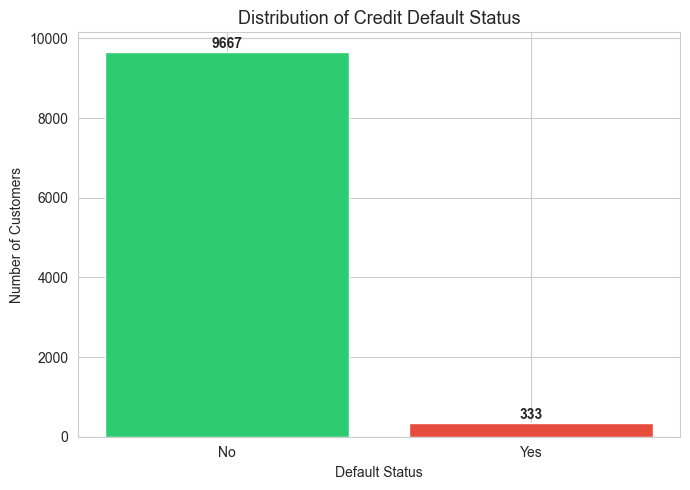

In [33]:
# Matplotlib #1 — Default status distribution
default_counts = df["defaulted"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(default_counts.index.astype(str), default_counts.values, color=["#2ecc71", "#e74c3c"])
plt.title("Distribution of Credit Default Status", fontsize=13)
plt.xlabel("Default Status")
plt.ylabel("Number of Customers")
for i, v in enumerate(default_counts.values):
    plt.text(i, v + 100, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

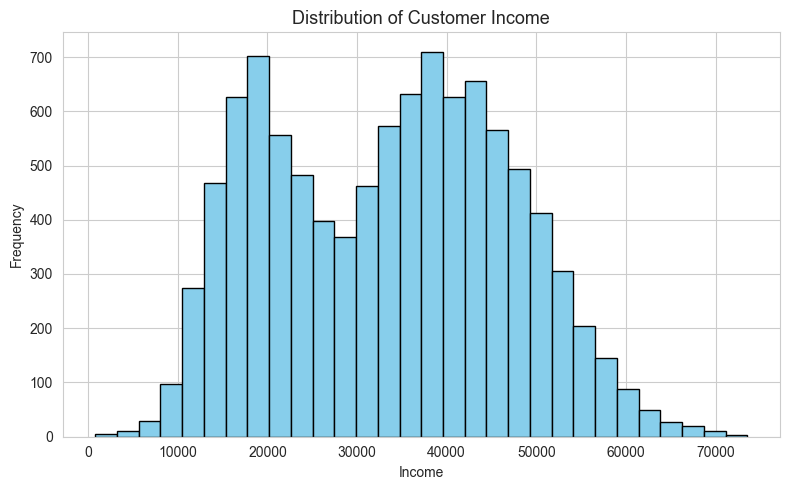

In [34]:
# Matplotlib #2 — Income distribution
plt.figure(figsize=(8, 5))
plt.hist(df["income"], bins=30, color="skyblue", edgecolor="black")
plt.title("Distribution of Customer Income", fontsize=13)
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

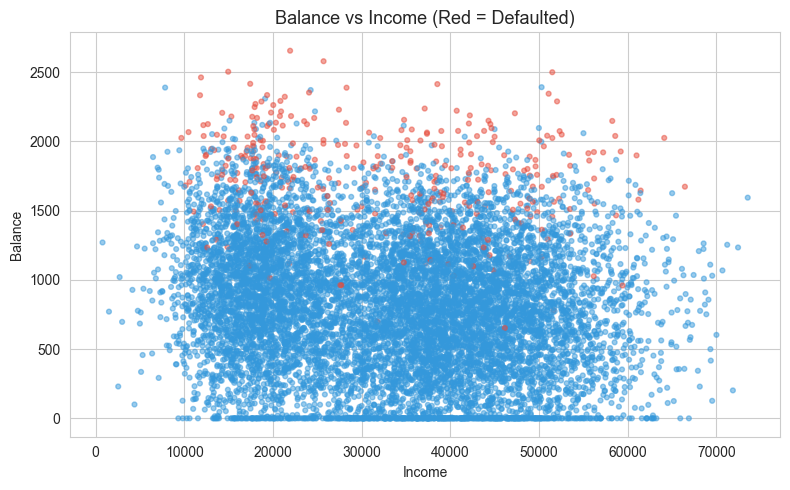

In [35]:
# Matplotlib #3 — Income vs Balance scatter, colored by default
colors = df["defaulted"].map({"No": "#3498db", "Yes": "#e74c3c"})

plt.figure(figsize=(8, 5))
plt.scatter(df["income"], df["balance"], c=colors, alpha=0.5, s=12)
plt.title("Balance vs Income (Red = Defaulted)", fontsize=13)
plt.xlabel("Income")
plt.ylabel("Balance")
plt.tight_layout()
plt.show()

C:\Users\RAJU\AppData\Local\Temp\ipykernel_3404\2500273556.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="defaulted", palette="Set2")


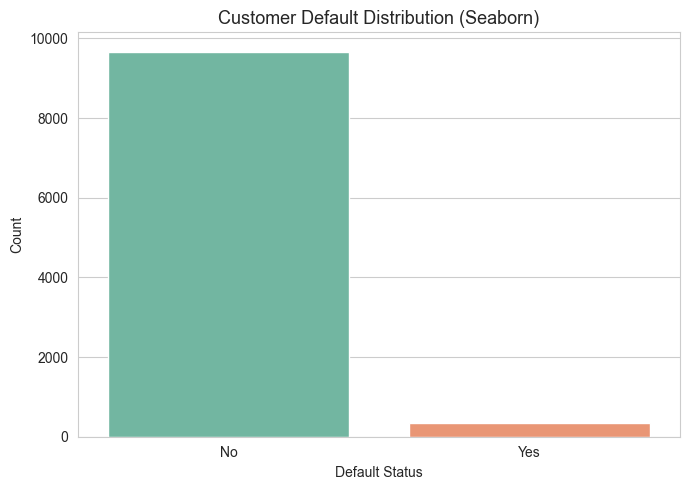

In [36]:
# Seaborn #1 — Countplot of default
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="defaulted", palette="Set2")
plt.title("Customer Default Distribution (Seaborn)", fontsize=13)
plt.xlabel("Default Status")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

C:\Users\RAJU\AppData\Local\Temp\ipykernel_3404\54740165.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="defaulted", y="balance", estimator="mean", errorbar=None, palette="Set1")


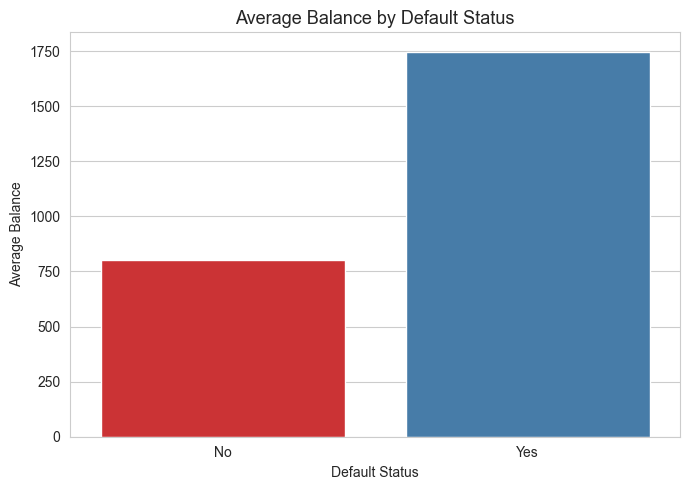

In [37]:
# Seaborn #2 — Average balance by default status
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="defaulted", y="balance", estimator="mean", errorbar=None, palette="Set1")
plt.title("Average Balance by Default Status", fontsize=13)
plt.xlabel("Default Status")
plt.ylabel("Average Balance")
plt.tight_layout()
plt.show()

C:\Users\RAJU\AppData\Local\Temp\ipykernel_3404\3535533623.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="defaulted", y="balance", palette="Set2")


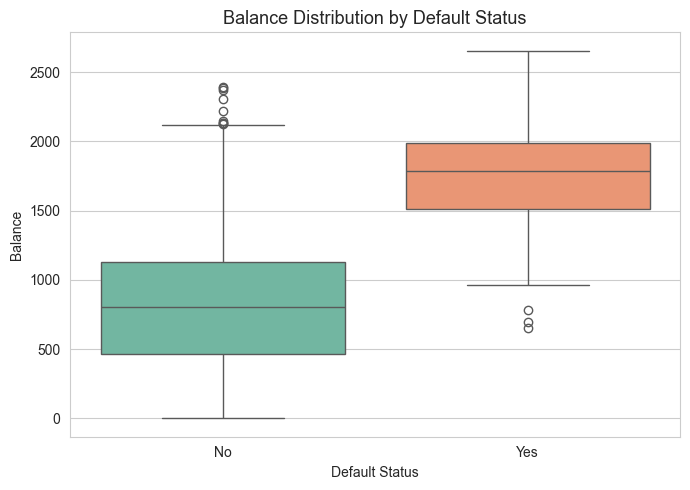

In [38]:
# Seaborn #3 — Balance distribution by default
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="defaulted", y="balance", palette="Set2")
plt.title("Balance Distribution by Default Status", fontsize=13)
plt.xlabel("Default Status")
plt.ylabel("Balance")
plt.tight_layout()
plt.show()

C:\Users\RAJU\AppData\Local\Temp\ipykernel_3404\3349420188.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="defaulted", y="income", palette="Set2")


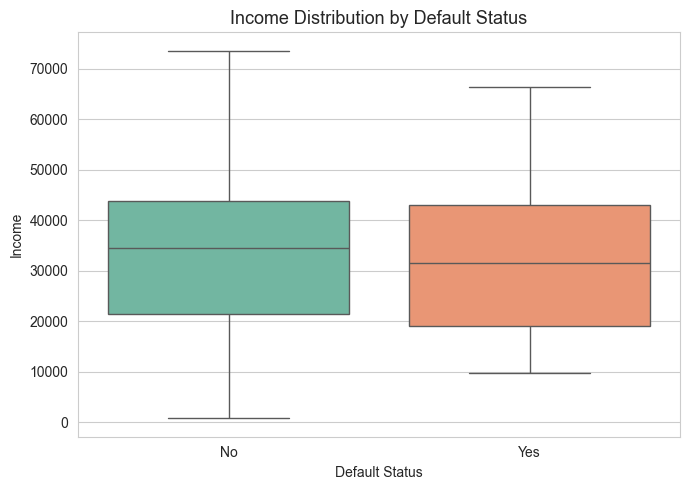

In [39]:
# Seaborn #4 — Income distribution by default
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="defaulted", y="income", palette="Set2")
plt.title("Income Distribution by Default Status", fontsize=13)
plt.xlabel("Default Status")
plt.ylabel("Income")
plt.tight_layout()
plt.show()

C:\Users\RAJU\AppData\Local\Temp\ipykernel_3404\4241482375.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rate_data, x="is_student", y="default_rate", palette="coolwarm")


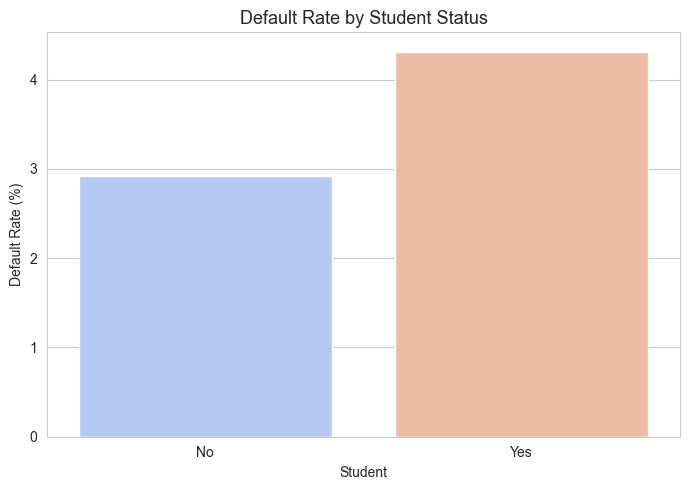

In [40]:
# Seaborn #5 — Default rate by student
rate_data = (df.groupby("is_student", observed=True)["default_flag"]
               .mean().mul(100).reset_index(name="default_rate"))

plt.figure(figsize=(7, 5))
sns.barplot(data=rate_data, x="is_student", y="default_rate", palette="coolwarm")
plt.title("Default Rate by Student Status", fontsize=13)
plt.xlabel("Student")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

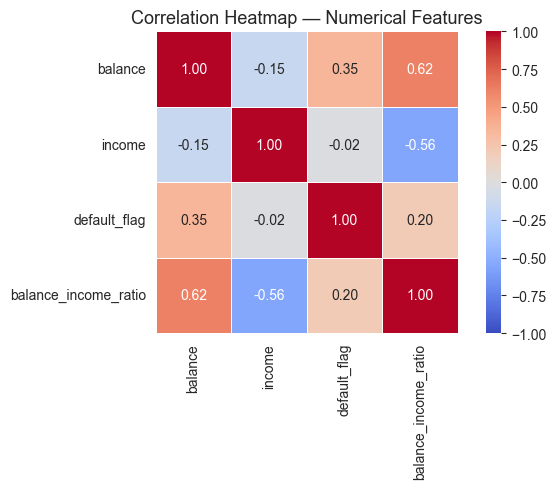

In [41]:
# Seaborn heatmap — correlation matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Heatmap — Numerical Features", fontsize=13)
plt.tight_layout()
plt.show()

In [42]:
# Save the fully cleaned and transformed dataset
df.to_csv("Default_cleaned.csv", index=False)
print("✅ Saved cleaned dataset as 'Default_cleaned.csv'")
print("Final shape:", df.shape)
print("Final columns:", df.columns.tolist())

✅ Saved cleaned dataset as 'Default_cleaned.csv'
Final shape: (10000, 9)
Final columns: ['defaulted', 'is_student', 'balance', 'income', 'balance_category', 'income_category', 'default_flag', 'risk_band', 'balance_income_ratio']


In [43]:
# Sanity check: verify final dataset
print("=== Final Dataset ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\nMissing values:", df.isnull().sum().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nFirst 3 rows:")
display(df.head(3))

=== Final Dataset ===
Rows: 10000, Columns: 9

Missing values: 0

Duplicate rows: 0

First 3 rows:


,defaulted,is_student,balance,income,balance_category,income_category,default_flag,risk_band,balance_income_ratio
0,No,No,729.526495,44361.625074,Low Balance,Medium Income,0,Low Risk,0.016445
1,No,Yes,817.180407,12106.134700,Low Balance,Low Income,0,Low Risk,0.067496
2,No,No,1073.549164,31767.138947,Medium Balance,Medium Income,0,Low Risk,0.033793
